# Experiment B — BiLSTM soil-moisture forecast, 72h horizon (FD11, 2015–2020)

Forecasts `SWC_20` (soil water content at 20 cm) at station `FD11`, **72 hours** after the end of a 24-hour
input window, with a small bidirectional LSTM, and compares it against naive baselines (last value, 24h moving
average). `experiment_a_48h.ipynb` (Experiment A, 48h horizon) runs the same pipeline independently.

**Pipeline:** data load → preprocessing / feature engineering → correlation check → chronological split →
greedy forward feature selection (fixed configuration) → retune on the selected features → final train →
evaluation.

| | |
|---|---|
| Data | `TxSON33_modeling_complete.parquet`, station `FD11`, hourly, 2015-01-01 00:00 to 2020-12-31 23:00 (2015–2020 inclusive) |
| Target | `SWC_20`; only `observed` readings are used as training targets or scored |
| Lookback / horizon | 24 hours / 72 hours: inputs cover hours `[t, t+23]`, the target is `SWC_20` at `t + 23 + 72` |
| Split | chronological 70% train / 10% validation (early stopping) / 20% test (used once, at the end) |
| Selection and retuning | `TimeSeriesSplit` cross-validation (`N_FOLDS` = 2) inside the 70% training block only |
| Selection config (fixed) | `num_layers=1`, `hidden_size=32`, `lr=0.005`, `batch_size=16` |
| Acceptance rule | a feature (group) is added only if it lowers mean CV RMSE by more than `REL_TOL` = 0.5% |
| Retune grid | `hidden_size` {32, 48} × `num_layers` {1, 2} × `lr` {0.001, 0.005}, `batch_size` 16 |
| Training | Adam, MSE loss, up to 30 epochs, early stopping patience 10 (CV fits and final model) |
| Baselines | last value (persistence) and 24h moving average, scored on exactly the same targets |

In [1]:
# --- Setup and reproducibility ---
import json
import os
import random
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import ParameterGrid, TimeSeriesSplit

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

PARQUET_PATH = "../TxSON33_modeling_complete.parquet"   # repo root, one level above this notebook
STATION = "FD11"
START_DATE = "2015-01-01"
END_DATE_EXCLUSIVE = "2021-01-01"      # 2015-2020 inclusive
PERIOD_LABEL = f"{START_DATE[:4]}-{int(END_DATE_EXCLUSIVE[:4]) - 1}"   # "2015-2020", for titles and file names
TARGET_COL = "SWC_20"
INITIAL_FEATURES = ["SWC_20", "Ppt_log"]   # mandatory inputs, never removed by feature selection
SEASON_COLS = ["season_Winter", "season_Spring", "season_Summer", "season_Fall"]
# Optional candidates for forward feature selection. Each entry is added or rejected as a whole, so the one-hot
# season and each sine/cosine pair stay complete. Raw Ppt is not a candidate (Ppt_log carries it).
CANDIDATE_GROUPS = {
    "Ppt_rolling_3h_log": ["Ppt_rolling_3h_log"], "Ppt_rolling_24h_log": ["Ppt_rolling_24h_log"],
    "Tair": ["Tair"], "RH": ["RH"], "Srad": ["Srad"],
    "SWC_5": ["SWC_5"], "SWC_10": ["SWC_10"], "SWC_50": ["SWC_50"],
    "T_5": ["T_5"], "T_10": ["T_10"], "T_20": ["T_20"], "T_50": ["T_50"],
    "Wx": ["Wx"], "Wy": ["Wy"],
    "season": SEASON_COLS,
    "hour_cyclic": ["hour_sin", "hour_cos"],
    "dayofyear_cyclic": ["dayofyear_sin", "dayofyear_cos"],
}
CANDIDATE_FEATURES = INITIAL_FEATURES + [c for cols in CANDIDATE_GROUPS.values() for c in cols]   # every possible input
WINDOW_SIZE = 24                       # hours of past data used as input
HORIZON = 72                           # target = SWC_20 this many hours after the window's last hour
EXPERIMENT_NAME = "Experiment B"

# Fixed configuration used for greedy feature selection (there is no initial grid search)
SELECTION_CONFIG = {"num_layers": 1, "hidden_size": 32, "lr": 0.005, "batch_size": 16}
# Retuning grid (8 combinations), searched once on the selected features
PARAM_GRID = {
    "num_layers": [1, 2],
    "hidden_size": [32, 48],
    "lr": [0.001, 0.005],
    "batch_size": [16],
}

TRAIN_FRAC, VAL_FRAC = 0.70, 0.10      # chronological split; the remaining 20% is the test block
EPOCHS = 30            # max epochs for the final model
TUNING_EPOCHS = 30     # max epochs for every cross-validated fit (feature selection and retuning)
PATIENCE = 10          # early stopping: stop after 10 epochs without validation improvement
N_FOLDS = 2  # Allowed values: 2, 3, or 4
if N_FOLDS not in (2, 3, 4):
    raise ValueError(f"N_FOLDS must be 2, 3 or 4 (TimeSeriesSplit folds inside the training data), got {N_FOLDS!r}")
REL_TOL = 0.005        # feature selection: an addition must lower mean CV RMSE by more than 0.5% to be kept
CORR_FLAG_THRESHOLD = 0.9   # correlation check: flag candidate inputs with |r| above this against SWC_20

# Plot colors: actual = ink, BiLSTM = blue, last-value baseline = orange, reference lines = gray
C_ACTUAL, C_MODEL, C_LAST, C_MUTED = "#0b0b0b", "#2a78d6", "#eb6834", "#8a8984"

# Selection history, retuning table, selected features and test metrics are saved here.
# In Colab, point this at a mounted Drive folder (e.g. "/content/drive/MyDrive/txson_outputs") to keep the files.
OUTPUT_DIR = "outputs_experiment_b_72h"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def output_path(name):
    return os.path.join(OUTPUT_DIR, f"{STATION}_{PERIOD_LABEL}_h{HORIZON}_{name}")

device: cpu


## 1. Load and inspect the data

Loading the parquet file, filtering to one station and 2015–2020 (the station's full history is kept aside for
the rolling rainfall features), and checking what that slice contains — including its `*_Origin` composition
(`observed` / `pipeline_imputed` / `modeling_completion`). The dataset's README is explicit that
`modeling_completion` values are synthetic and should not be used as validation or test ground truth.

In [2]:
raw = pd.read_parquet(PARQUET_PATH)
raw["Timestamp"] = pd.to_datetime(raw["Timestamp"])

# Full, chronologically sorted station history -- kept so the rolling rainfall features (Section 2) can use the
# hours before START_DATE -- and the modeling period START_DATE <= Timestamp < END_DATE_EXCLUSIVE
station_df = raw[raw["Station"] == STATION].copy()
station_df = station_df.sort_values("Timestamp").set_index("Timestamp")
df = station_df[(station_df.index >= START_DATE) & (station_df.index < END_DATE_EXCLUSIVE)].copy()

RAW_INPUT_COLS = ["SWC_20", "Ppt", "Wind speed", "Wind direction", "Tair", "RH", "Srad",
                  "SWC_5", "SWC_10", "SWC_50", "T_5", "T_10", "T_20", "T_50"]
expected_rows = len(pd.date_range(START_DATE, END_DATE_EXCLUSIVE, freq="h", inclusive="left"))

print("Shape:", df.shape, f"(a complete hourly {PERIOD_LABEL} has {expected_rows} rows)")
print("Date range:", df.index.min(), "to", df.index.max())
print("Duplicate timestamps:", df.index.duplicated().sum())
print("Hourly and gap-free:", (df.index.to_series().diff().dropna() == pd.Timedelta("1h")).all())
print(f"Full {STATION} history (for rolling features):", station_df.index.min(), "to", station_df.index.max())
print()
print("Missing values in the columns used below:")
print(df[RAW_INPUT_COLS].isna().sum().to_dict())
print()
print("Origin composition of every raw input column (modeling_completion = synthetic):")
print(pd.DataFrame({c: df[f"{c}_Origin"].value_counts() for c in RAW_INPUT_COLS}).T.fillna(0).astype(int))
print()
print("Hours where the target is not an observed reading:",
      [str(t) for t in df.index[df["SWC_20_Origin"] != "observed"]])

Shape: (52608, 32) (a complete hourly 2015-2020 has 52608 rows)
Date range: 2015-01-01 00:00:00 to 2020-12-31 23:00:00
Duplicate timestamps: 0
Hourly and gap-free: True
Full FD11 history (for rolling features): 2014-11-12 18:00:00 to 2025-07-16 15:00:00

Missing values in the columns used below:
{'SWC_20': 0, 'Ppt': 0, 'Wind speed': 0, 'Wind direction': 0, 'Tair': 0, 'RH': 0, 'Srad': 0, 'SWC_5': 0, 'SWC_10': 0, 'SWC_50': 0, 'T_5': 0, 'T_10': 0, 'T_20': 0, 'T_50': 0}

Origin composition of every raw input column (modeling_completion = synthetic):
                observed  pipeline_imputed  modeling_completion
SWC_20             52604                 4                    0
Ppt                52606                 2                    0
Wind speed             0                 0                52608
Wind direction         0                 0                52608
Tair                   0                 0                52608
RH                     0                 0                52608


**What this shows:** 52,608 hourly rows for 2015–2020 with no missing values and no duplicate or missing
timestamps. `SWC_20` is `observed` for every hour except 4 `pipeline_imputed` ones (2016-03-14 00:00,
2016-11-07 01:00, 2019-10-24 16:00, 2019-11-18 12:00) and `Ppt` for every hour except 2 (2016-03-14 00:00,
2019-10-24 16:00); neither has any `modeling_completion` (synthetic) values, so the wider period keeps the same
data quality that originally justified 2018–2020. Any window whose target hour is not an `observed` `SWC_20`
reading is dropped from training, validation and test scoring (the two 2016 hours fall in the training block, the
two 2019 hours in the test block).

The soil sensors (`SWC_5/10/50`, `T_5/10/20/50`) are also >99.9% `observed`. The meteorological columns (`Tair`,
`RH`, `Srad`, `Wind speed`, `Wind direction`) are **100% `modeling_completion`** at `FD11`: they remain
feature-selection candidates (inputs are not ground truth), but a selected meteorological feature carries
modeled, not measured, information.

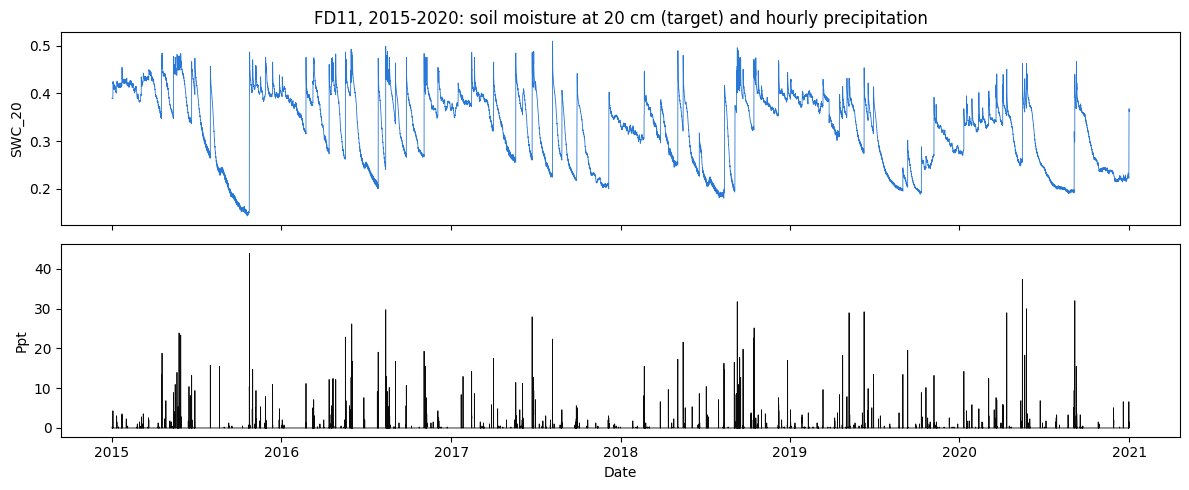

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(df.index, df["SWC_20"], linewidth=0.6, color=C_MODEL)
axes[0].set_ylabel("SWC_20")
axes[0].set_title(f"{STATION}, {PERIOD_LABEL}: soil moisture at 20 cm (target) and hourly precipitation")
axes[1].plot(df.index, df["Ppt"], linewidth=0.6, color=C_ACTUAL)
axes[1].set_ylabel("Ppt")
axes[1].set_xlabel("Date")
plt.tight_layout()
plt.show()

`SWC_20` shows a slow-drydown-with-sharp-rises pattern: soil moisture creeps down between rain events and jumps
when it rains. The drydown depends on how wet the soil has been over the preceding hours, and the rises line up
with precipitation — which is why precipitation is a mandatory input.

## 2. Preprocessing and feature engineering

### Precipitation

`log1p(Ppt)` compresses the long right tail (mostly zero, occasional storms). Negative readings are clipped to
zero first as a defensive step (`log1p` is undefined below -1); there are none in this period.

### Rolling rainfall

`Ppt_rolling_3h_log` and `Ppt_rolling_24h_log` are `log1p` of the total rainfall over the 3 / 24 hours
**before** each hour (`shift(1)`: the current hour is excluded, since `Ppt_log` already carries it). They are
computed on the full, chronologically sorted `FD11` history and then attached to the 2015–2020 rows, so the first
hours of 2015 are initialized from real late-2014 rainfall. A missing hour is never counted as zero rain: each sum
needs every hour of its window (`min_periods` = window length, on a complete hourly grid), so an incomplete window
stays `NaN` and is trimmed from the start of the period (none are expected; the history begins 2014-11-12).

In [4]:
n_negative = int((df["Ppt"] < 0).sum())
print(f"Negative Ppt readings found: {n_negative} out of {len(df)}")

df["Ppt"] = df["Ppt"].fillna(0.0).clip(lower=0.0)   # defensive; no-op for this station/period
df["Ppt_log"] = np.log1p(df["Ppt"])


def rolling_ppt_log(ppt, hours):
    """log1p of the total rainfall over the `hours` hours BEFORE each timestamp (the current hour is excluded).

    ppt: chronologically sorted hourly series. It is put on a complete hourly grid first, so a missing row or a
    NaN reading makes that window's sum NaN (min_periods = hours) instead of silently counting as zero rain.
    """
    ppt = ppt.asfreq("h")
    return np.log1p(ppt.shift(1).rolling(hours, min_periods=hours).sum())


ROLLING_PPT_COLS = ["Ppt_rolling_3h_log", "Ppt_rolling_24h_log"]
# Computed on the full station history (negatives clipped as above, missing values left as NaN) and then
# assigned to the 2015-2020 rows, aligned on Timestamp
history_ppt = station_df["Ppt"].clip(lower=0.0)
df["Ppt_rolling_3h_log"] = rolling_ppt_log(history_ppt, 3)
df["Ppt_rolling_24h_log"] = rolling_ppt_log(history_ppt, 24)

# Explicit warm-up handling: NaN means part of that hour's rolling window is missing from the history
incomplete = df[ROLLING_PPT_COLS].isna().any(axis=1)
print(f"Rows whose rolling-rainfall window is incomplete: {int(incomplete.sum())} of {len(df)}")
if incomplete.any():
    first_complete = incomplete.idxmin()
    assert not incomplete.loc[first_complete:].any(), "incomplete rolling windows after the warm-up; check Ppt gaps"
    print(f"Dropping {int(incomplete.loc[:first_complete].sum())} leading warm-up rows; "
          f"modeling starts at {first_complete}")
    df = df.loc[first_complete:].copy()

Negative Ppt readings found: 0 out of 52608
Rows whose rolling-rainfall window is incomplete: 0 of 52608


### Wind

`Wind speed` and `Wind direction` have spaces in their column names in this dataset, so bracket access is needed.
Direction is circular (359° and 1° are nearly the same direction), so speed + direction is converted into a 2D
vector `(Wx, Wy)`; when the wind is calm both components shrink toward 0 regardless of direction. `Wx` and `Wy`
are optional selection candidates.

In [5]:
wv = df["Wind speed"].fillna(0.0).clip(lower=0.0)
wd_rad = df["Wind direction"] * np.pi / 180.0
df["Wx"] = wv * np.cos(wd_rad)
df["Wy"] = wv * np.sin(wd_rad)

### Calendar features

Derived from each row's own `Timestamp`, so they are known in advance for every hour:

- **Meteorological season**, one-hot: Winter = Dec–Feb, Spring = Mar–May, Summer = Jun–Aug, Fall = Sep–Nov.
- **Hour of day** as `hour_sin` / `hour_cos` (period 24 h), so 23:00 and 00:00 are neighbours.
- **Day of year** as `dayofyear_sin` / `dayofyear_cos` (period = that year's length, 365 or 366 days), so
  31 Dec and 1 Jan are neighbours.

In feature selection each encoding is one group (`season`, `hour_cyclic`, `dayofyear_cyclic`).

In [6]:
def add_calendar_features(data_df):
    """Adds one-hot meteorological season and hour / day-of-year sine-cosine pairs, from the Timestamp index."""
    idx = data_df.index
    season = np.select([idx.month.isin([12, 1, 2]), idx.month.isin([3, 4, 5]), idx.month.isin([6, 7, 8])],
                       ["Winter", "Spring", "Summer"], default="Fall")
    for col in SEASON_COLS:                                   # season_Winter, season_Spring, ...
        data_df[col] = (season == col.removeprefix("season_")).astype(np.float32)
    data_df["hour_sin"] = np.sin(2 * np.pi * idx.hour / 24)
    data_df["hour_cos"] = np.cos(2 * np.pi * idx.hour / 24)
    days_in_year = np.where(idx.is_leap_year, 366, 365)
    data_df["dayofyear_sin"] = np.sin(2 * np.pi * (idx.dayofyear - 1) / days_in_year)
    data_df["dayofyear_cos"] = np.cos(2 * np.pi * (idx.dayofyear - 1) / days_in_year)
    return data_df


df = add_calendar_features(df)
assert (df[SEASON_COLS].sum(axis=1) == 1).all()   # exactly one season per hour
assert not df[CANDIDATE_FEATURES].isna().any().any(), "a model input contains NaN"

## 3. Correlation check (training period only)

For every candidate input, its Pearson correlation with the `SWC_20` target over the same hours — one number per
feature, the equivalent of `cor(df$feature, df$SWC_20)`. It is computed on the **training period only** (the
first 70% of rows, the same block as the split in Section 4), so validation and test data never inform a
preprocessing decision.

A feature with |r| above `CORR_FLAG_THRESHOLD` (0.9) is flagged: such a feature can act as a disguised
persistence signal — the model "predicting" `SWC_20` by reading a closely correlated sensor rather than learning
the dynamics. `SWC_5` (shallow, so it could track `SWC_20` closely) and `T_20` (soil temperature at the target
depth) are reported explicitly.

In [7]:
train_period = df.iloc[:int(len(df) * TRAIN_FRAC)]    # the training block of Section 4; nothing later
corr_table = pd.DataFrame({"r": {c: train_period[c].corr(train_period[TARGET_COL])
                                 for c in CANDIDATE_FEATURES if c != TARGET_COL}})
corr_table = corr_table.sort_values("r", ascending=False)
corr_table["flag"] = np.where(corr_table["r"].abs() > CORR_FLAG_THRESHOLD, "HIGH", "")
FLAGGED_FEATURES = list(corr_table.index[corr_table["flag"] == "HIGH"])

print(f"Pearson r with {TARGET_COL}, training period {train_period.index.min()} -> {train_period.index.max()} "
      f"({len(train_period)} rows), highest to lowest:")
print(corr_table.round(3).to_string())
print()
for col in ["SWC_5", "T_20"]:
    print(f"{col}: r = {corr_table.loc[col, 'r']:.3f}" + ("  <- FLAGGED" if col in FLAGGED_FEATURES else ""))
print(f"Flagged (|r| > {CORR_FLAG_THRESHOLD}):", FLAGGED_FEATURES or "none")

Pearson r with SWC_20, training period 2015-01-01 00:00:00 -> 2019-03-15 08:00:00 (36825 rows), highest to lowest:
                         r flag
SWC_10               0.843     
SWC_50               0.819     
SWC_5                0.726     
dayofyear_sin        0.330     
dayofyear_cos        0.319     
season_Winter        0.292     
Ppt_rolling_24h_log  0.291     
RH                   0.225     
season_Spring        0.188     
Ppt_rolling_3h_log   0.174     
Wx                   0.154     
Ppt_log              0.113     
hour_cos             0.013     
hour_sin            -0.011     
Wy                  -0.108     
Srad                -0.140     
season_Fall         -0.202     
season_Summer       -0.294     
Tair                -0.368     
T_5                 -0.432     
T_10                -0.469     
T_20                -0.492     
T_50                -0.502     

SWC_5: r = 0.726
T_20: r = -0.492
Flagged (|r| > 0.9): none


**What this shows:** no candidate is flagged. The strongest correlations are the neighbouring soil-moisture
sensors — `SWC_10` (0.84), `SWC_50` (0.82) and `SWC_5` (0.73) — all below 0.9; `SWC_5` tracks `SWC_20` less
closely than the deeper sensors do. Since `SWC_5` is not flagged, the with/without-`SWC_5` test comparison is not
needed. `T_20` is present in the dataset (>99.9% `observed`) and is already a selection candidate; its correlation
is −0.49 (soil is wetter when it is cooler), in line with the other soil temperatures.

## 4. Chronological train / validation / test split (70 / 10 / 20)

Chronological, not random: training data comes entirely before validation data, which comes entirely before test
data.

- **Train (70%)** — fits the model. Feature selection and retuning run on cross-validation folds *inside* this
  block only.
- **Validation (10%)** — used only for early stopping of the final model.
- **Test (20%)** — touched once, at the very end, to compare the BiLSTM against the naive baselines.

In [8]:
n = len(df)
n_train = int(n * TRAIN_FRAC)
n_val = int(n * VAL_FRAC)

train_df = df.iloc[:n_train]
val_df = df.iloc[n_train:n_train + n_val]
test_df = df.iloc[n_train + n_val:]

print(f"train: {len(train_df):5d} rows  {train_df.index.min()} -> {train_df.index.max()}")
print(f"val:   {len(val_df):5d} rows  {val_df.index.min()} -> {val_df.index.max()}")
print(f"test:  {len(test_df):5d} rows  {test_df.index.min()} -> {test_df.index.max()}")
assert train_df.index.max() < val_df.index.min() < val_df.index.max() < test_df.index.min()
assert train_df.index.equals(train_period.index)   # the correlation check used exactly this block

print()
print("Test-period SWC_20 origin composition (must be observed ground truth, not synthetic):")
print(test_df["SWC_20_Origin"].value_counts().to_dict())

train: 36825 rows  2015-01-01 00:00:00 -> 2019-03-15 08:00:00
val:    5260 rows  2019-03-15 09:00:00 -> 2019-10-20 12:00:00
test:  10523 rows  2019-10-20 13:00:00 -> 2020-12-31 23:00:00

Test-period SWC_20 origin composition (must be observed ground truth, not synthetic):
{'observed': 10521, 'pipeline_imputed': 2, 'modeling_completion': 0}


## 5. Normalization

`MinMaxScaler`, fit on the training split only and reused (never refit) for validation and test, so their
distributions never leak into preprocessing. Validation/test values can legitimately fall outside `[0, 1]`.

In [9]:
scaler = MinMaxScaler()
scaler.fit(train_df[CANDIDATE_FEATURES])   # fit on TRAIN ONLY; per-column, so any feature subset is scaled the same

def scale(split_df, cols=CANDIDATE_FEATURES, fitted_scaler=scaler):
    arr = fitted_scaler.transform(split_df[cols]).astype(np.float32)
    return pd.DataFrame(arr, columns=cols, index=split_df.index)


def unscale_target(values, fitted_scaler=scaler):
    """Scaled SWC_20 values back to original SWC_20 units."""
    pos = list(fitted_scaler.feature_names_in_).index(TARGET_COL)
    lo, hi = fitted_scaler.data_min_[pos], fitted_scaler.data_max_[pos]
    return np.asarray(values, dtype=np.float64) * (hi - lo) + lo


train_scaled = scale(train_df)
val_scaled = scale(val_df)
test_scaled = scale(test_df)
assert np.allclose(train_scaled.min(), 0) and np.allclose(train_scaled.max(), 1)   # train is exactly [0, 1]

## 6. Building X/Y windows

A 24-hour window slides across the hourly data; each position is one example `X`, and its label `y` is `SWC_20`
exactly `HORIZON` hours after the window's last hour: inputs at rows `[start, end - 1]`, target at
`end - 1 + HORIZON`. Written as an explicit loop so every step is visible.

Windows are built **separately inside each partition** (train / validation / test, and each CV fold's two parts),
so an input window and its target never straddle a boundary. Windows whose target hour is not an `observed`
`SWC_20` reading are dropped after windowing (never the source rows), so every kept window still ends exactly
`HORIZON` hours before its target.

In [10]:
def make_windows(data_df, feature_cols, target_col, window_size, horizon):
    """
    data_df: chronologically ordered, already-scaled dataframe.
    window_size: number of past hours used as input (X).
    horizon: how many hours AFTER the window's last hour the target sits.

    Returns X (num_samples, window_size, num_features), y (num_samples,), and the row-index
    (within data_df) of each window's last input hour / its target hour, for verification.
    """
    values = data_df[feature_cols].values
    targets = data_df[target_col].values
    n = len(data_df)

    X, y, end_idx, target_idx = [], [], [], []
    for start in range(0, n - window_size - horizon + 1):
        end = start + window_size          # first index AFTER the window (exclusive)
        tgt = end - 1 + horizon            # horizon hours after the window's LAST hour (end - 1)
        X.append(values[start:end])
        y.append(targets[tgt])
        end_idx.append(end - 1)
        target_idx.append(tgt)

    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32), end_idx, target_idx


def check_window_alignment(index, end_idx, target_idx, window_size, horizon):
    """Asserts every input covers `window_size` consecutive hourly steps and every target is exactly `horizon`
    hours after its window's last input hour, all inside the partition that `index` belongs to."""
    index = pd.DatetimeIndex(index)
    end_idx, target_idx = np.asarray(end_idx), np.asarray(target_idx)
    assert len(target_idx) > 0, "partition too short for one window"
    assert (np.diff(index.values) == np.timedelta64(1, "h")).all(), "partition is not consecutive hourly data"
    start_idx = end_idx - (window_size - 1)
    assert start_idx.min() >= 0 and target_idx.max() < len(index)       # nothing outside this partition
    assert ((index[end_idx] - index[start_idx]) == pd.Timedelta(hours=window_size - 1)).all()
    assert ((index[target_idx] - index[end_idx]) == pd.Timedelta(hours=horizon)).all()


def observed_target_mask(split_index, target_idx):
    """True for windows whose target hour has an observed SWC_20 reading. pipeline_imputed and synthetic
    modeling_completion values are never used as training targets or as validation/test ground truth."""
    origin = df[f"{TARGET_COL}_Origin"].reindex(split_index).to_numpy()
    return origin[np.asarray(target_idx, dtype=int)] == "observed"


def observed_windows(split_df, split_scaled, feature_cols):
    """Windows of one partition whose target is an observed SWC_20 reading: X, y (scaled), end_idx, target_idx."""
    X, y, end_idx, target_idx = make_windows(split_scaled, feature_cols, TARGET_COL, WINDOW_SIZE, HORIZON)
    keep = observed_target_mask(split_df.index, target_idx)
    return X[keep], y[keep], np.asarray(end_idx)[keep], np.asarray(target_idx)[keep]

In [11]:
# Worked example with real timestamps: first, middle and last training window. The scaled target, converted
# back, must equal the SWC_20 value looked up by the target's TIMESTAMP (independent of the index arithmetic).
X_demo, y_demo, end_idx_demo, target_idx_demo = make_windows(
    train_scaled, INITIAL_FEATURES, TARGET_COL, WINDOW_SIZE, HORIZON)
for i in (0, len(y_demo) // 2, len(y_demo) - 1):
    t_start = train_df.index[end_idx_demo[i] - (WINDOW_SIZE - 1)]
    t_end, t_tgt = train_df.index[end_idx_demo[i]], train_df.index[target_idx_demo[i]]
    y_orig = unscale_target(y_demo[i])
    print(f"window {i:5d}: inputs {t_start} -> {t_end} | target {t_tgt} "
          f"(+{(t_tgt - t_end) / pd.Timedelta(hours=1):.0f}h) | y = {y_orig:.4f}, "
          f"SWC_20 at {t_tgt} = {df.loc[t_tgt, TARGET_COL]:.4f}")
    assert t_tgt - t_end == pd.Timedelta(hours=HORIZON)
    assert abs(y_orig - df.loc[t_tgt, TARGET_COL]) < 1e-6
print(f"X dims: {X_demo.shape} = (num_samples, window_size, num_features);  y dims: {y_demo.shape}")

# Every window of every partition: 24 consecutive hourly inputs, target exactly HORIZON hours after the last input,
# never across a partition boundary; plus the count of windows dropped for a non-observed target
exclusions = {}
for part_name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    _, _, end_idx, target_idx = make_windows(part, [TARGET_COL], TARGET_COL, WINDOW_SIZE, HORIZON)
    check_window_alignment(part.index, end_idx, target_idx, WINDOW_SIZE, HORIZON)
    keep = observed_target_mask(part.index, target_idx)
    exclusions[part_name] = {"windows": len(keep), "observed_targets": int(keep.sum()),
                             "non_observed_targets_dropped": int((~keep).sum())}
print(f"Window alignment checks passed for the {HORIZON}h horizon in train, val and test.")
pd.DataFrame(exclusions).T

window     0: inputs 2015-01-01 00:00:00 -> 2015-01-01 23:00:00 | target 2015-01-04 23:00:00 (+72h) | y = 0.4170, SWC_20 at 2015-01-04 23:00:00 = 0.4170
window 18365: inputs 2017-02-04 05:00:00 -> 2017-02-05 04:00:00 | target 2017-02-08 04:00:00 (+72h) | y = 0.3810, SWC_20 at 2017-02-08 04:00:00 = 0.3810
window 36729: inputs 2019-03-11 09:00:00 -> 2019-03-12 08:00:00 | target 2019-03-15 08:00:00 (+72h) | y = 0.3990, SWC_20 at 2019-03-15 08:00:00 = 0.3990
X dims: (36730, 24, 2) = (num_samples, window_size, num_features);  y dims: (36730,)
Window alignment checks passed for the 72h horizon in train, val and test.


,windows,observed_targets,non_observed_targets_dropped
train,36730,36728,2
val,5165,5165,0
test,10428,10426,2


## 7. A simple bidirectional LSTM

An `nn.LSTM` with `batch_first=True` reads the 24-hour input sequence, and one `nn.Linear` layer maps the LSTM's
final summary to a single predicted value (structure after the GeeksforGeeks PyTorch LSTM tutorial,
[Long Short-Term Memory Networks using PyTorch](https://www.geeksforgeeks.org/deep-learning/long-short-term-memory-networks-using-pytorch/)),
made **bidirectional** and summarized from `h_n`.

```
input        (batch, 24 hours, F features)         <- SWC_20, Ppt_log + selected features; batch_first=True
nn.LSTM(input_size=F, hidden_size=H, num_layers=L, batch_first=True, bidirectional=True)
  forward direction  reads hour 1 -> hour 24  -> final hidden state h_fwd  (batch, H)
  backward direction reads hour 24 -> hour 1  -> final hidden state h_bwd  (batch, H)
concat [h_fwd, h_bwd]                    (batch, 2H)
Linear(2H -> 1)                           <- predicted SWC_20 (scaled) at window end + HORIZON
```

- **LSTM cell:** at every hour the forget, input and output gates update a cell state (long-term memory) and a
  hidden state, which lets the model carry "it rained 10 hours ago" or "the soil has been drying steadily"
  forward through the window, in order.
- **`bidirectional=True` is not leakage:** the backward direction only reads hours *inside* the already-observed
  input window, never the target hour, which is `HORIZON` hours after the window ends.
- **Why `h_n` rather than `out[:, -1, :]`:** for a bidirectional LSTM, `out[:, -1, :]` holds the backward state
  after only one hour (the backward pass *starts* at hour 24). `h_n[-2]` (forward) and `h_n[-1]` (backward) are
  each direction's final state after reading all 24 hours, always from the last layer.
- **Initial states:** PyTorch uses zero `h0`/`c0` when none are passed; each window starts from a blank memory.

| Setting | Value | Notes |
|---|---|---|
| `num_layers` | 1 during selection; retuned over {1, 2} | fixed for selection, then 8-combination grid |
| `hidden_size` | 32 during selection; retuned over {32, 48} | per direction |
| `lr` | 0.005 during selection; retuned over {0.001, 0.005} | Adam |
| `batch_size` | 16 | fixed |
| window | 24 hours | fixed |
| loss | MSE | minimizing MSE also minimizes RMSE, the selection score |
| epochs | up to 30, early stopping patience 10 | the best-validation epoch's weights are restored |

Related soil-moisture LSTM work, for context: Kim, Lee, Chung et al. (2026),
[*Development of long short-term memory models using rainfall and soil moisture to predict soil moisture dynamics*](https://journals.plos.org/plosone/article?id=10.1371%2Fjournal.pone.0353268),
PLOS ONE — the closest setup (hourly in-situ soil moisture plus rainfall, MinMax scaling, chronological splits,
grid search); errors grew with forecast horizon.

In [12]:
class SimpleBiLSTM(nn.Module):
    def __init__(self, num_features, hidden_size, num_layers):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=num_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
        )
        self.fc = nn.Linear(2 * hidden_size, 1)           # 2x: forward + backward summaries concatenated

    def forward(self, x):
        # x: (batch, 24, num_features)
        _, (h_n, _) = self.lstm(x)          # h_n: (num_layers * 2, batch, hidden_size); h0/c0 default to zeros
        h_forward = h_n[-2]                 # last layer, forward direction  (read hour 1 -> 24)
        h_backward = h_n[-1]                # last layer, backward direction (read hour 24 -> 1)
        h = torch.cat([h_forward, h_backward], dim=1)   # -> (batch, 2 * hidden_size)
        return self.fc(h)                   # -> (batch, 1)


def build_bilstm(config, num_features):
    return SimpleBiLSTM(num_features, hidden_size=config["hidden_size"], num_layers=config["num_layers"])

## 8. Evaluation metrics

MSE, RMSE (√MSE, in `SWC_20` units — the score used for feature selection and retuning), MAE, SMAPE, RSE and
CORR, written from their definitions and sanity-checked on known cases. MAPE is included for reference only:
it divides by the actual value, and although `SWC_20` (roughly 0.18–0.5) is never near zero, SMAPE is the
more robust percentage error.

In [13]:
def compute_metrics(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true, dtype=np.float64).flatten()
    y_pred = np.asarray(y_pred, dtype=np.float64).flatten()

    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_true - y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / (np.abs(y_true) + eps))) * 100
    smape = np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + eps)) * 100
    rse = np.sum((y_pred - y_true) ** 2) / (np.sum((y_true - y_true.mean()) ** 2) + eps)
    corr = np.corrcoef(y_true, y_pred)[0, 1] if min(np.std(y_true), np.std(y_pred)) > 1e-12 else float("nan")

    return {"MSE": mse, "RMSE": rmse, "MAE": mae, "MAPE": mape, "SMAPE": smape, "RSE": rse, "CORR": corr}


# Sanity checks against known cases
perfect = compute_metrics([1, 2, 3], [1, 2, 3])
assert perfect["MSE"] == 0 and perfect["MAE"] == 0 and abs(perfect["CORR"] - 1.0) < 1e-9
assert abs(compute_metrics([1.0], [0.0])["MAPE"] - 100.0) < 1e-6
assert abs(compute_metrics([0.0, 0.0], [3.0, 4.0])["RMSE"] - np.sqrt(12.5)) < 1e-12

## 9. Training loop and training helpers

A plain, manual PyTorch loop: Adam, MSE, early stopping on the validation loss with the best epoch's weights
restored. `train_model` returns the per-epoch training and validation losses, so the number of epochs run and the
best epoch are always known. `run_final` trains one model on the 70% training block (early-stopped on the 10%
validation block) and predicts every observed-target window of train, validation and test, in original `SWC_20`
units.

In [14]:
def train_model(model, train_loader, val_loader, epochs=EPOCHS, patience=PATIENCE, lr=1e-3):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    train_losses, val_losses = [], []
    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(epochs):
        model.train()                          # training mode
        running_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
        train_loss = running_loss / len(train_loader.dataset)
        train_losses.append(train_loss)

        model.eval()                           # evaluation mode
        val_running = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                pred = model(xb)
                val_running += criterion(pred, yb).item() * xb.size(0)
        val_loss = val_running / len(val_loader.dataset)
        val_losses.append(val_loss)

        if val_loss < best_val_loss - 1e-7:
            best_val_loss = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state)      # restore the best-validation epoch

    return model, train_losses, val_losses, best_epoch


def make_loaders(X_train, y_train, X_val, y_val, batch_size, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(TensorDataset(torch.tensor(X_train), torch.tensor(y_train).unsqueeze(1)),
                              batch_size=batch_size, shuffle=True, generator=g)
    val_loader = DataLoader(TensorDataset(torch.tensor(X_val), torch.tensor(y_val).unsqueeze(1)),
                            batch_size=batch_size)
    return train_loader, val_loader


def predict(model, X, batch_size=256):
    """Scaled predictions for X, in order."""
    model.eval()
    with torch.no_grad():
        return torch.cat([model(torch.tensor(X[i:i + batch_size]).to(DEVICE)).cpu()
                          for i in range(0, len(X), batch_size)]).numpy().flatten()


def run_final(feature_cols, config, epochs=EPOCHS, patience=PATIENCE, seed=SEED):
    """Trains one model on the training block (early stopping on the validation block) and predicts every
    observed-target window of train, val and test. Predictions and targets are in original SWC_20 units."""
    t0 = time.time()
    splits = {"train": (train_df, train_scaled), "val": (val_df, val_scaled), "test": (test_df, test_scaled)}
    windows = {name: observed_windows(part, part_s, feature_cols) for name, (part, part_s) in splits.items()}
    train_loader, val_loader = make_loaders(*windows["train"][:2], *windows["val"][:2], config["batch_size"], seed)

    torch.manual_seed(seed)
    model = build_bilstm(config, len(feature_cols))
    model, train_losses, val_losses, best_epoch = train_model(model, train_loader, val_loader, epochs=epochs,
                                                              patience=patience, lr=config["lr"])
    result = {"features": list(feature_cols), "config": config, "train_losses": train_losses,
              "val_losses": val_losses, "best_epoch": best_epoch, "epochs_run": len(train_losses)}
    for name, (part, _) in splits.items():
        X, _, end_idx, target_idx = windows[name]
        result[name] = {"y_true": part[TARGET_COL].to_numpy()[target_idx],      # observed values, unscaled
                        "y_pred": unscale_target(predict(model, X)),
                        "end_time": part.index[end_idx], "target_time": part.index[target_idx]}
    result["runtime_sec"] = time.time() - t0
    return result

## 10. Naive baselines: last value and moving average

Two models with nothing to learn, scored on **exactly the same targets** as the BiLSTM (same windows, same
horizon, same observed-target filter):

- **Last value (persistence):** `SWC_20` at the target time equals `SWC_20` at the window's last hour.
- **Moving average (24h):** the mean `SWC_20` over the 24-hour input window.

Computed from the **unscaled** partitions, for train, validation and test (the training-set comparison is what
tells "learning the task" apart from "memorizing persistence" in Section 15).

In [15]:
def naive_baselines(data_df, ma_window=WINDOW_SIZE):
    """True targets and naive predictions for every window with an observed target, in original SWC_20 units."""
    X, y, _, target_idx = make_windows(data_df, [TARGET_COL], TARGET_COL, WINDOW_SIZE, HORIZON)
    keep = observed_target_mask(data_df.index, target_idx)   # same targets as the BiLSTM
    swc = X[keep, :, 0]
    return y[keep], {
        "Last value": swc[:, -1],
        f"Moving average ({ma_window}h)": swc[:, -ma_window:].mean(axis=1),
    }


naive = {name: naive_baselines(part) for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]}
NAIVE_NAMES = list(naive["test"][1])

## 11. Time-series cross-validation folds

Feature selection and retuning are scored **inside the 70% training block only**, with
`sklearn.model_selection.TimeSeriesSplit` (`N_FOLDS` = 2): the block is cut into `N_FOLDS + 1` consecutive chunks;
fold 1 trains on chunk 1 and validates on chunk 2, fold 2 trains on chunks 1–2 and validates on chunk 3. Each fold
trains on the past and validates on the period right after it. With six years of data, fold 1's training part
now covers more than a full seasonal cycle.

**Inside each fold:** a new `MinMaxScaler` is fit on the fold's training part only; windows are built separately
for each part; non-observed targets are dropped; the model trains for up to `TUNING_EPOCHS` (30) epochs with
patience 10; and the fold's score is the RMSE of its validation predictions in original `SWC_20` units. A
configuration + feature set is scored by its **mean validation RMSE across the folds**.

In [16]:
tscv = TimeSeriesSplit(n_splits=N_FOLDS)
cv_folds = list(tscv.split(train_df))
assert len(cv_folds) == N_FOLDS

for k, (tr_idx, va_idx) in enumerate(cv_folds, start=1):
    tr, va = train_df.iloc[tr_idx], train_df.iloc[va_idx]
    assert tr.index.max() < va.index.min()   # always train on the past, validate on the future
    dropped = {}
    for part_name, part in (("train", tr), ("val", va)):   # windows are built inside each part
        _, _, end_idx, target_idx = make_windows(part, [TARGET_COL], TARGET_COL, WINDOW_SIZE, HORIZON)
        check_window_alignment(part.index, end_idx, target_idx, WINDOW_SIZE, HORIZON)
        dropped[part_name] = int((~observed_target_mask(part.index, target_idx)).sum())
    print(f"fold {k}: train {len(tr):5d} rows {tr.index.min():%Y-%m-%d} -> {tr.index.max():%Y-%m-%d} "
          f"({len(tr) / 24 / 30.44:.1f} months) | val {len(va):5d} rows {va.index.min():%Y-%m-%d} -> "
          f"{va.index.max():%Y-%m-%d} ({len(va) / 24 / 30.44:.1f} months) | non-observed targets dropped: {dropped}")

fold 1: train 12275 rows 2015-01-01 -> 2016-05-26 (16.8 months) | val 12275 rows 2016-05-26 -> 2017-10-19 (16.8 months) | non-observed targets dropped: {'train': 1, 'val': 1}
fold 2: train 24550 rows 2015-01-01 -> 2017-10-19 (33.6 months) | val 12275 rows 2017-10-19 -> 2019-03-15 (16.8 months) | non-observed targets dropped: {'train': 2, 'val': 0}


In [17]:
def cv_score(config, feature_cols, epochs=TUNING_EPOCHS):
    """Validation RMSE of `config` with `feature_cols` on each TimeSeriesSplit fold, in original SWC_20 units,
    observed targets only. Returns (mean RMSE, per-fold RMSEs, per-fold best epochs, per-fold epochs run)."""
    scale_cols = list(dict.fromkeys(list(feature_cols) + [TARGET_COL]))   # inputs + target, no duplicates
    fold_rmses, best_epochs, epochs_run = [], [], []
    for tr_idx, va_idx in cv_folds:
        fold_train, fold_val = train_df.iloc[tr_idx], train_df.iloc[va_idx]
        fold_scaler = MinMaxScaler().fit(fold_train[scale_cols])        # fit on this fold's training part only
        Xtr, ytr, _, _ = observed_windows(fold_train, scale(fold_train, scale_cols, fold_scaler), feature_cols)
        Xv, yv, _, va_tgt = observed_windows(fold_val, scale(fold_val, scale_cols, fold_scaler), feature_cols)
        train_loader, val_loader = make_loaders(Xtr, ytr, Xv, yv, config["batch_size"])

        torch.manual_seed(SEED)
        model = build_bilstm(config, len(feature_cols))
        model, train_losses, _, best_epoch = train_model(model, train_loader, val_loader, epochs=epochs,
                                                         patience=PATIENCE, lr=config["lr"])
        # RMSE of the restored best-epoch model, in original SWC_20 units
        pred = unscale_target(predict(model, Xv), fold_scaler)
        y_true = fold_val[TARGET_COL].to_numpy()[va_tgt]                # observed values, unscaled
        fold_rmses.append(float(compute_metrics(y_true, pred)["RMSE"]))
        best_epochs.append(best_epoch)
        epochs_run.append(len(train_losses))
    return float(np.mean(fold_rmses)), fold_rmses, best_epochs, epochs_run


_cv_cache = {}   # avoids re-running an identical (features, config) CV evaluation

def cached_cv_score(config, feature_cols):
    key = (N_FOLDS, tuple(feature_cols), tuple(sorted(config.items())))
    if key not in _cv_cache:
        _cv_cache[key] = cv_score(config, feature_cols)
    return _cv_cache[key]


def fold_columns(fold_rmses, best_epochs, epochs_run):
    return {**{f"fold{k}_RMSE": r for k, r in enumerate(fold_rmses, start=1)},
            **{f"fold{k}_best_epoch": e for k, e in enumerate(best_epochs, start=1)},
            **{f"fold{k}_epochs_run": e for k, e in enumerate(epochs_run, start=1)}}

## 12. Greedy forward feature selection (fixed configuration)

Scored by the CV above, with the fixed `SELECTION_CONFIG` (`num_layers=1`, `hidden_size=32`, `lr=0.005`,
`batch_size=16`); **the test set is never touched here**.

1. Start from the mandatory `INITIAL_FEATURES = ["SWC_20", "Ppt_log"]` (never removed) and compute its mean CV
   RMSE.
2. Try adding each remaining entry of `CANDIDATE_GROUPS` — a single column, or the `season` / `hour_cyclic` /
   `dayofyear_cyclic` encoding as a whole.
3. Take the addition with the lowest mean CV RMSE and accept it only if
   `best_rmse < current * (1 - REL_TOL)`, i.e. it lowers the current mean RMSE by more than 0.5%.
4. Stop as soon as the best addition does not clear that bar, or when no candidates remain.

The history table records, per step, the best candidate, whether it was accepted, the RMSE before and after, the
bar it had to beat (`required_below`), its fold RMSEs and epochs, and the stopping reason.

In [18]:
def greedy_forward_selection(config, candidate_groups=CANDIDATE_GROUPS):
    """Forward selection scored only by mean CV RMSE on the training folds (never the test set). Starts from the
    mandatory INITIAL_FEATURES and stops at the first step whose best addition does not lower the current mean
    RMSE by more than REL_TOL (relative), or when no candidates remain."""
    selected = list(INITIAL_FEATURES)                     # mandatory, never removed
    remaining = dict(candidate_groups)
    current, *folds = cached_cv_score(config, selected)
    step_rows = [{"step": 0, "candidate": "(start)", "accepted": True, "RMSE_before": np.nan,
                  "required_below": np.nan, "candidate_mean_RMSE": current, "RMSE_after": current,
                  "std_val_RMSE": float(np.std(folds[0])), **fold_columns(*folds),
                  "selected_features": list(selected), "stop_reason": ""}]
    candidate_scores = {}   # candidate_scores[step][candidate] = mean CV RMSE when that candidate is added
    print(f"Start: {selected}, mean val RMSE={current:.6f}")

    step, stop_reason = 0, "no candidates remain"
    while remaining:
        step += 1
        required = current * (1 - REL_TOL)
        print(f"\n--- Step {step}: adding one of {len(remaining)} candidates to {selected} "
              f"(needs mean val RMSE < {required:.6f}) ---")
        scores = {}
        for name, cols in remaining.items():
            t0 = time.time()
            scores[name] = cached_cv_score(config, selected + cols)   # (mean RMSE, fold RMSEs, best epochs, epochs run)
            print(f"  + {name:20s}: mean val RMSE={scores[name][0]:.6f}  ({time.time() - t0:.0f}s)")
        best = min(scores, key=lambda name: scores[name][0])
        candidate_scores[step] = {name: s[0] for name, s in scores.items()}
        best_rmse, *best_folds = scores[best]
        accepted = best_rmse < current * (1 - REL_TOL)
        if accepted:
            selected = selected + remaining.pop(best)
        else:
            stop_reason = (f"best addition '{best}' did not lower mean CV RMSE by more than {REL_TOL:.1%} "
                           f"({best_rmse:.6f}, needed < {required:.6f})")
        step_rows.append({"step": step, "candidate": best, "accepted": accepted, "RMSE_before": current,
                          "required_below": required, "candidate_mean_RMSE": best_rmse,
                          "RMSE_after": best_rmse if accepted else current,
                          "std_val_RMSE": float(np.std(best_folds[0])), **fold_columns(*best_folds),
                          "selected_features": list(selected), "stop_reason": ""})
        print(f"  -> {'accepted' if accepted else 'rejected'} {best}: {current:.6f} -> {best_rmse:.6f}")
        if not accepted:
            break
        current = best_rmse

    step_rows[-1]["stop_reason"] = stop_reason
    print(f"\nStopped: {stop_reason}.\nSelected features: {selected}")
    return selected, pd.DataFrame(step_rows).set_index("step"), candidate_scores, stop_reason


print(f"===== {EXPERIMENT_NAME}: feature selection, {HORIZON}h horizon, config {SELECTION_CONFIG}, "
      f"{N_FOLDS} folds, up to {TUNING_EPOCHS} epochs (patience {PATIENCE}), REL_TOL={REL_TOL} =====")
selected_features, selection_history, candidate_scores, stop_reason = greedy_forward_selection(SELECTION_CONFIG)
selection_history.to_csv(output_path("feature_selection_history.csv"))
with open(output_path("selected_features.json"), "w") as f:
    json.dump({"horizon": HORIZON, "selected_features": selected_features, "stop_reason": stop_reason,
               "selection_config": SELECTION_CONFIG, "rel_tol": REL_TOL}, f, indent=2)
display(selection_history)

===== Experiment B: feature selection, 72h horizon, config {'num_layers': 1, 'hidden_size': 32, 'lr': 0.005, 'batch_size': 16}, 2 folds, up to 30 epochs (patience 10), REL_TOL=0.005 =====


Start: ['SWC_20', 'Ppt_log'], mean val RMSE=0.038183

--- Step 1: adding one of 17 candidates to ['SWC_20', 'Ppt_log'] (needs mean val RMSE < 0.037992) ---


  + Ppt_rolling_3h_log  : mean val RMSE=0.037976  (207s)


  + Ppt_rolling_24h_log : mean val RMSE=0.038328  (215s)


  + Tair                : mean val RMSE=0.038226  (217s)


...

  + Wy                  : mean val RMSE=0.037658  (297s)


  + season              : mean val RMSE=0.039483  (247s)


  + hour_cyclic         : mean val RMSE=0.038149  (277s)


  + dayofyear_cyclic    : mean val RMSE=0.040656  (215s)
  -> rejected Wy: 0.037628 -> 0.037658

Stopped: best addition 'Wy' did not lower mean CV RMSE by more than 0.5% (0.037658, needed < 0.037440).
Selected features: ['SWC_20', 'Ppt_log', 'T_5', 'Ppt_rolling_24h_log']


,candidate,accepted,RMSE_before,required_below,candidate_mean_RMSE,RMSE_after,std_val_RMSE,fold1_RMSE,fold2_RMSE,fold1_best_epoch,fold2_best_epoch,fold1_epochs_run,fold2_epochs_run,selected_features,stop_reason
step,,,,,,,,,,,,,,,
0,(start),True,NaN,NaN,0.038183,0.038183,0.004332,0.042515,0.033851,4,4,14,14,"[SWC_20, Ppt_log]",
1,T_5,True,0.038183,0.037992,0.037966,0.037966,0.004236,0.042202,0.033730,9,7,19,17,"[SWC_20, Ppt_log, T_5]",
2,Ppt_rolling_24h_log,True,0.037966,0.037776,0.037628,0.037628,0.003267,0.040895,0.034360,13,4,23,14,"[SWC_20, Ppt_log, T_5, Ppt_rolling_24h_log]",
3,Wy,False,0.037628,0.037440,0.037658,0.037628,0.004076,0.041734,0.033582,9,2,19,12,"[SWC_20, Ppt_log, T_5, Ppt_rolling_24h_log]",best addition 'Wy' did not lower mean CV RMSE ...


In [19]:
# Mean CV RMSE of every candidate tried at every step (blank = already selected); the step's best is highlighted
candidate_table = pd.DataFrame(candidate_scores).T.reindex(columns=list(CANDIDATE_GROUPS))
candidate_table.index.name = "step"
display(candidate_table.style.format("{:.6f}", na_rep="").highlight_min(axis=1, color="lightgreen"))

,Ppt_rolling_3h_log,Ppt_rolling_24h_log,Tair,RH,Srad,SWC_5,SWC_10,SWC_50,T_5,T_10,T_20,T_50,Wx,Wy,season,hour_cyclic,dayofyear_cyclic
step,,,,,,,,,,,,,,,,,
1,0.037976,0.038328,0.038226,0.038437,0.039072,0.039697,0.038417,0.039873,0.037966,0.038573,0.038335,0.038579,0.038510,0.038277,0.040158,0.038270,0.042532
2,0.037898,0.037628,0.038366,0.038508,0.038469,0.040147,0.038319,0.039450,,0.038620,0.038522,0.038685,0.038202,0.038090,0.039424,0.038270,0.041223
3,0.037971,,0.038039,0.038306,0.038328,0.039390,0.038389,0.038534,,0.037766,0.037927,0.038512,0.038210,0.037658,0.039483,0.038149,0.040656


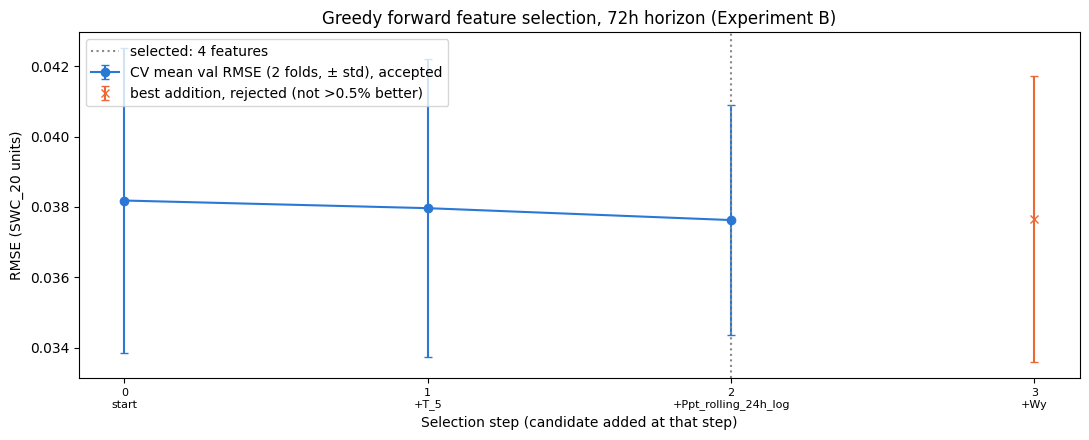

In [20]:
acc, rej = selection_history[selection_history["accepted"]], selection_history[~selection_history["accepted"]]
plt.figure(figsize=(11, 4.5))
plt.errorbar(acc.index, acc["candidate_mean_RMSE"], yerr=acc["std_val_RMSE"], marker="o", capsize=3,
             color=C_MODEL, label=f"CV mean val RMSE ({N_FOLDS} folds, ± std), accepted")
if len(rej):
    plt.errorbar(rej.index, rej["candidate_mean_RMSE"], yerr=rej["std_val_RMSE"], marker="x", capsize=3,
                 linestyle="none", color=C_LAST, label=f"best addition, rejected (not >{REL_TOL:.1%} better)")
plt.axvline(acc.index.max(), color=C_MUTED, linestyle=":", label=f"selected: {len(selected_features)} features")
plt.xticks(selection_history.index,
           ["0\nstart" if s == 0 else f"{s}\n+{c}" for s, c in zip(selection_history.index,
                                                                  selection_history["candidate"])], fontsize=8)
plt.xlabel("Selection step (candidate added at that step)")
plt.ylabel("RMSE (SWC_20 units)")
plt.title(f"Greedy forward feature selection, {HORIZON}h horizon ({EXPERIMENT_NAME})")
plt.legend()
plt.tight_layout()
plt.show()

## 13. Retuning on the selected features

The 8-combination grid (`ParameterGrid(PARAM_GRID)`: `num_layers` {1, 2} × `hidden_size` {32, 48} × `lr`
{0.001, 0.005}, `batch_size` 16) is scored on the same folds using **only the selected features**; the lowest
mean CV RMSE gives the final configuration. The fixed selection configuration is one of the 8 combinations, so
its score is read from the CV cache rather than re-trained.

In [21]:
def grid_search_cv(feature_cols, param_grid=PARAM_GRID):
    """Scores every ParameterGrid combination on the same CV folds. Returns (table sorted by mean validation
    RMSE, best config)."""
    grid = list(ParameterGrid(param_grid))
    print(f"--- Grid search: {len(grid)} configs, {HORIZON}h horizon, features={list(feature_cols)}, "
          f"{N_FOLDS} folds, up to {TUNING_EPOCHS} epochs (patience {PATIENCE}) ---")
    rows = []
    for i, config in enumerate(grid, start=1):
        t0 = time.time()
        mean_rmse, *folds = cached_cv_score(config, list(feature_cols))
        rows.append({**config, "mean_val_RMSE": mean_rmse, "std_val_RMSE": float(np.std(folds[0])),
                     **fold_columns(*folds)})
        print(f"  [{i}/{len(grid)}] {config}: mean val RMSE={mean_rmse:.6f}  ({time.time() - t0:.0f}s)")
    best_row = min(rows, key=lambda r: r["mean_val_RMSE"])
    best_config = {k: best_row[k] for k in param_grid}
    print(f"  -> best config: {best_config} (mean val RMSE={best_row['mean_val_RMSE']:.6f})")
    return pd.DataFrame(rows).sort_values("mean_val_RMSE").reset_index(drop=True), best_config


retune_grid, final_config = grid_search_cv(selected_features)
retune_grid.to_csv(output_path("retune_grid_search.csv"), index=False)
display(retune_grid)

--- Grid search: 8 configs, 72h horizon, features=['SWC_20', 'Ppt_log', 'T_5', 'Ppt_rolling_24h_log'], 2 folds, up to 30 epochs (patience 10) ---


  [1/8] {'batch_size': 16, 'hidden_size': 32, 'lr': 0.001, 'num_layers': 1}: mean val RMSE=0.037959  (234s)


  [2/8] {'batch_size': 16, 'hidden_size': 32, 'lr': 0.001, 'num_layers': 2}: mean val RMSE=0.037831  (7902s)
  [3/8] {'batch_size': 16, 'hidden_size': 32, 'lr': 0.005, 'num_layers': 1}: mean val RMSE=0.037628  (0s)


  [4/8] {'batch_size': 16, 'hidden_size': 32, 'lr': 0.005, 'num_layers': 2}: mean val RMSE=0.037905  (145133s)


  [5/8] {'batch_size': 16, 'hidden_size': 48, 'lr': 0.001, 'num_layers': 1}: mean val RMSE=0.037801  (296s)


  [6/8] {'batch_size': 16, 'hidden_size': 48, 'lr': 0.001, 'num_layers': 2}: mean val RMSE=0.037897  (475s)


  [7/8] {'batch_size': 16, 'hidden_size': 48, 'lr': 0.005, 'num_layers': 1}: mean val RMSE=0.037876  (165s)


  [8/8] {'batch_size': 16, 'hidden_size': 48, 'lr': 0.005, 'num_layers': 2}: mean val RMSE=0.037886  (386s)
  -> best config: {'num_layers': 1, 'hidden_size': 32, 'lr': 0.005, 'batch_size': 16} (mean val RMSE=0.037628)


,batch_size,hidden_size,lr,num_layers,mean_val_RMSE,std_val_RMSE,fold1_RMSE,fold2_RMSE,fold1_best_epoch,fold2_best_epoch,fold1_epochs_run,fold2_epochs_run
0,16,32,0.005,1,0.037628,0.003267,0.040895,0.034360,13,4,23,14
1,16,48,0.001,1,0.037801,0.003865,0.041666,0.033936,4,7,14,17
2,16,32,0.001,2,0.037831,0.003422,0.041252,0.034409,4,1,14,11
3,16,48,0.005,1,0.037876,0.003638,0.041513,0.034238,4,2,14,12
4,16,48,0.005,2,0.037886,0.003740,0.041626,0.034146,9,1,19,11
5,16,48,0.001,2,0.037897,0.003450,0.041347,0.034447,4,5,14,15
6,16,32,0.005,2,0.037905,0.004004,0.041909,0.033902,4,1,14,11
7,16,32,0.001,1,0.037959,0.003572,0.041531,0.034387,4,1,14,11


## 14. Final model

Trained on the 70% training block (scaler fit there only) with the selected features and the retuned
configuration, early-stopped on the 10% validation block (up to 30 epochs, patience 10, best-validation weights
restored), then evaluated once on the 20% test block.

In [22]:
print(f"{EXPERIMENT_NAME}: training the {HORIZON}h model, config {final_config}, features {selected_features} ...")
final = run_final(selected_features, final_config)
print(f"  epochs run: {final['epochs_run']} (max {EPOCHS}, patience {PATIENCE}); best epoch: {final['best_epoch']}; "
      f"{final['runtime_sec']:.0f}s")

# the BiLSTM and the naive baselines must be scored on the identical targets
for name in ("train", "val", "test"):
    assert np.allclose(final[name]["y_true"], naive[name][0], atol=1e-6)

with open(output_path("tuning_summary.json"), "w") as f:
    json.dump({"experiment": EXPERIMENT_NAME, "horizon": HORIZON, "selection_config": SELECTION_CONFIG,
               "rel_tol": REL_TOL, "selected_features": selected_features, "selection_stop_reason": stop_reason,
               "final_config": final_config, "final_cv_RMSE": float(retune_grid["mean_val_RMSE"].iloc[0]),
               "final_best_epoch": final["best_epoch"], "final_epochs_run": final["epochs_run"],
               "max_epochs": EPOCHS, "patience": PATIENCE}, f, indent=2)

Experiment B: training the 72h model, config {'num_layers': 1, 'hidden_size': 32, 'lr': 0.005, 'batch_size': 16}, features ['SWC_20', 'Ppt_log', 'T_5', 'Ppt_rolling_24h_log'] ...


  epochs run: 22 (max 30, patience 10); best epoch: 12; 232s


### 14.1 Training and validation loss per epoch

How to read the two curves: both falling and then levelling off together means the model is learning; training
loss still falling while validation loss rises means overfitting; both flat from the first epoch or two (with the
best epoch near the start) means a plateau — the model reached a low-loss solution almost immediately and further
epochs do not move it. Losses are MSE on the scaled target.

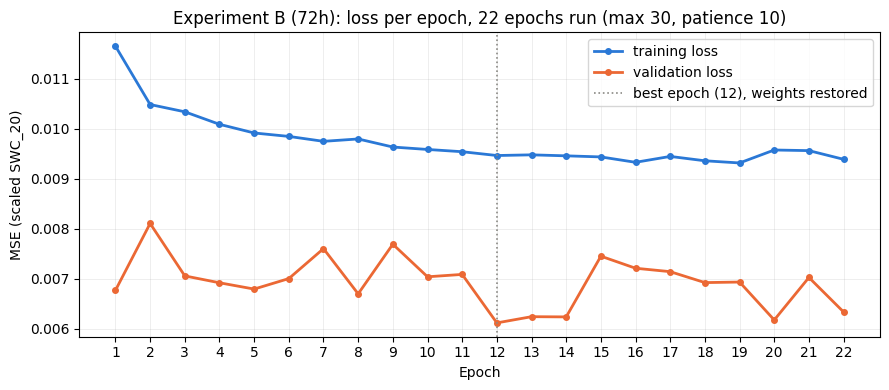

In [23]:
epochs_axis = np.arange(1, final["epochs_run"] + 1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(epochs_axis, final["train_losses"], color=C_MODEL, linewidth=2, marker="o", markersize=4,
        label="training loss")
ax.plot(epochs_axis, final["val_losses"], color=C_LAST, linewidth=2, marker="o", markersize=4,
        label="validation loss")
ax.axvline(final["best_epoch"], color=C_MUTED, linestyle=":", linewidth=1.2,
           label=f"best epoch ({final['best_epoch']}), weights restored")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE (scaled SWC_20)")
ax.set_xticks(epochs_axis)
ax.set_title(f"{EXPERIMENT_NAME} ({HORIZON}h): loss per epoch, {final['epochs_run']} epochs run "
             f"(max {EPOCHS}, patience {PATIENCE})")
ax.grid(alpha=0.3, linewidth=0.5)
ax.legend()
plt.tight_layout()
plt.show()

## 15. Evaluation

### 15.1 Test metrics and the persistence check

The first table compares the BiLSTM with the naive baselines on the test block. The second reports RMSE on
**every** partition against the same baselines on identical targets; `skill_vs_last_value` = 1 − RMSE(BiLSTM) /
RMSE(last value), positive when the model beats persistence. Beating persistence on training data but not on
validation/test indicates overfitting; failing to beat it even on training data means the model is not learning
the task.

In [24]:
METRIC_COLS = ["MSE", "RMSE", "MAE", "MAPE", "SMAPE", "RSE", "CORR"]

y_true_test, naive_test = naive["test"]
test_table = pd.DataFrame({f"BiLSTM ({EXPERIMENT_NAME})": compute_metrics(final["test"]["y_true"],
                                                                          final["test"]["y_pred"]),
                           **{name: compute_metrics(y_true_test, pred) for name, pred in naive_test.items()}}
                          ).T[METRIC_COLS]
test_table.index.name = f"{HORIZON}h horizon, test"
test_table.to_csv(output_path("test_metrics.csv"))
display(test_table)
print(f"Features: {selected_features}\nConfig:   {final_config}")

persistence_rows = {}
for name in ("train", "val", "test"):
    y_true, preds = naive[name]
    rmse_model = compute_metrics(final[name]["y_true"], final[name]["y_pred"])["RMSE"]
    rmse_last = compute_metrics(y_true, preds["Last value"])["RMSE"]
    persistence_rows[name] = {"BiLSTM_RMSE": rmse_model, "last_value_RMSE": rmse_last,
                              "moving_average_RMSE": compute_metrics(y_true, preds[NAIVE_NAMES[1]])["RMSE"],
                              "skill_vs_last_value": 1 - rmse_model / rmse_last, "n_targets": len(y_true)}
persistence_table = pd.DataFrame(persistence_rows).T
persistence_table.index.name = "partition"
display(persistence_table.astype({"n_targets": int}).round(5))

,MSE,RMSE,MAE,MAPE,SMAPE,RSE,CORR
"72h horizon, test",,,,,,,
BiLSTM (Experiment B),0.000698,0.026427,0.016541,5.631115,5.619009,0.188838,0.902758
Last value,0.000661,0.025715,0.012980,3.954455,4.128886,0.178792,0.910377
Moving average (24h),0.000702,0.026502,0.013708,4.219079,4.409765,0.189904,0.904154


Features: ['SWC_20', 'Ppt_log', 'T_5', 'Ppt_rolling_24h_log']
Config:   {'num_layers': 1, 'hidden_size': 32, 'lr': 0.005, 'batch_size': 16}


,BiLSTM_RMSE,last_value_RMSE,moving_average_RMSE,skill_vs_last_value,n_targets
partition,,,,,
train,0.03574,0.04058,0.04216,0.11926,36728
val,0.02869,0.02583,0.02648,-0.11084,5165
test,0.02643,0.02571,0.02650,-0.02771,10426


### 15.2 Alignment check on real timestamps

A handful of test windows, evenly spaced through the test block: the input window, the target timestamp, the
prediction, the actual `SWC_20` looked up **by that timestamp** in the full dataframe, and the last-value
baseline. The assert checks the same timestamp lookup for every scored test target, so the plots below draw each
prediction at the hour it is a forecast for.

In [25]:
t = final["test"]
assert np.allclose(t["y_true"], df.loc[t["target_time"], TARGET_COL].to_numpy())
assert ((t["target_time"] - t["end_time"]) == pd.Timedelta(hours=HORIZON)).all()
pick = np.linspace(0, len(t["y_pred"]) - 1, 8).astype(int)
display(pd.DataFrame({
    "input_start": t["end_time"][pick] - pd.Timedelta(hours=WINDOW_SIZE - 1),
    "input_end": t["end_time"][pick],
    "target_time": t["target_time"][pick],
    "predicted": t["y_pred"][pick],
    "actual": df.loc[t["target_time"][pick], TARGET_COL].to_numpy(),
    "last_value": naive_test["Last value"][pick],
}).round(4))

,input_start,input_end,target_time,predicted,actual,last_value
0,2019-10-20 13:00:00,2019-10-21 12:00:00,2019-10-24 12:00:00,0.2965,0.257,0.265
1,2019-12-21 16:00:00,2019-12-22 15:00:00,2019-12-25 15:00:00,0.2857,0.283,0.277
2,2020-02-21 17:00:00,2020-02-22 16:00:00,2020-02-25 16:00:00,0.3461,0.340,0.348
3,2020-04-23 18:00:00,2020-04-24 17:00:00,2020-04-27 17:00:00,0.3191,0.300,0.324
4,2020-06-24 20:00:00,2020-06-25 19:00:00,2020-06-28 19:00:00,0.2614,0.248,0.253
5,2020-08-25 21:00:00,2020-08-26 20:00:00,2020-08-29 20:00:00,0.1994,0.198,0.196
6,2020-10-26 22:00:00,2020-10-27 21:00:00,2020-10-30 21:00:00,0.2701,0.241,0.240
7,2020-12-28 00:00:00,2020-12-28 23:00:00,2020-12-31 23:00:00,0.2372,0.362,0.229


### 15.3 Test period by month

One panel per calendar month of the test block, by target time (each panel's y-axis is scaled to that month so
small errors and lags stay visible). The last-value baseline is the actual series shifted right by exactly
72 hours; where the BiLSTM line sits on top of it, the model is effectively predicting "no change". The moving
average baseline is in the tables above.

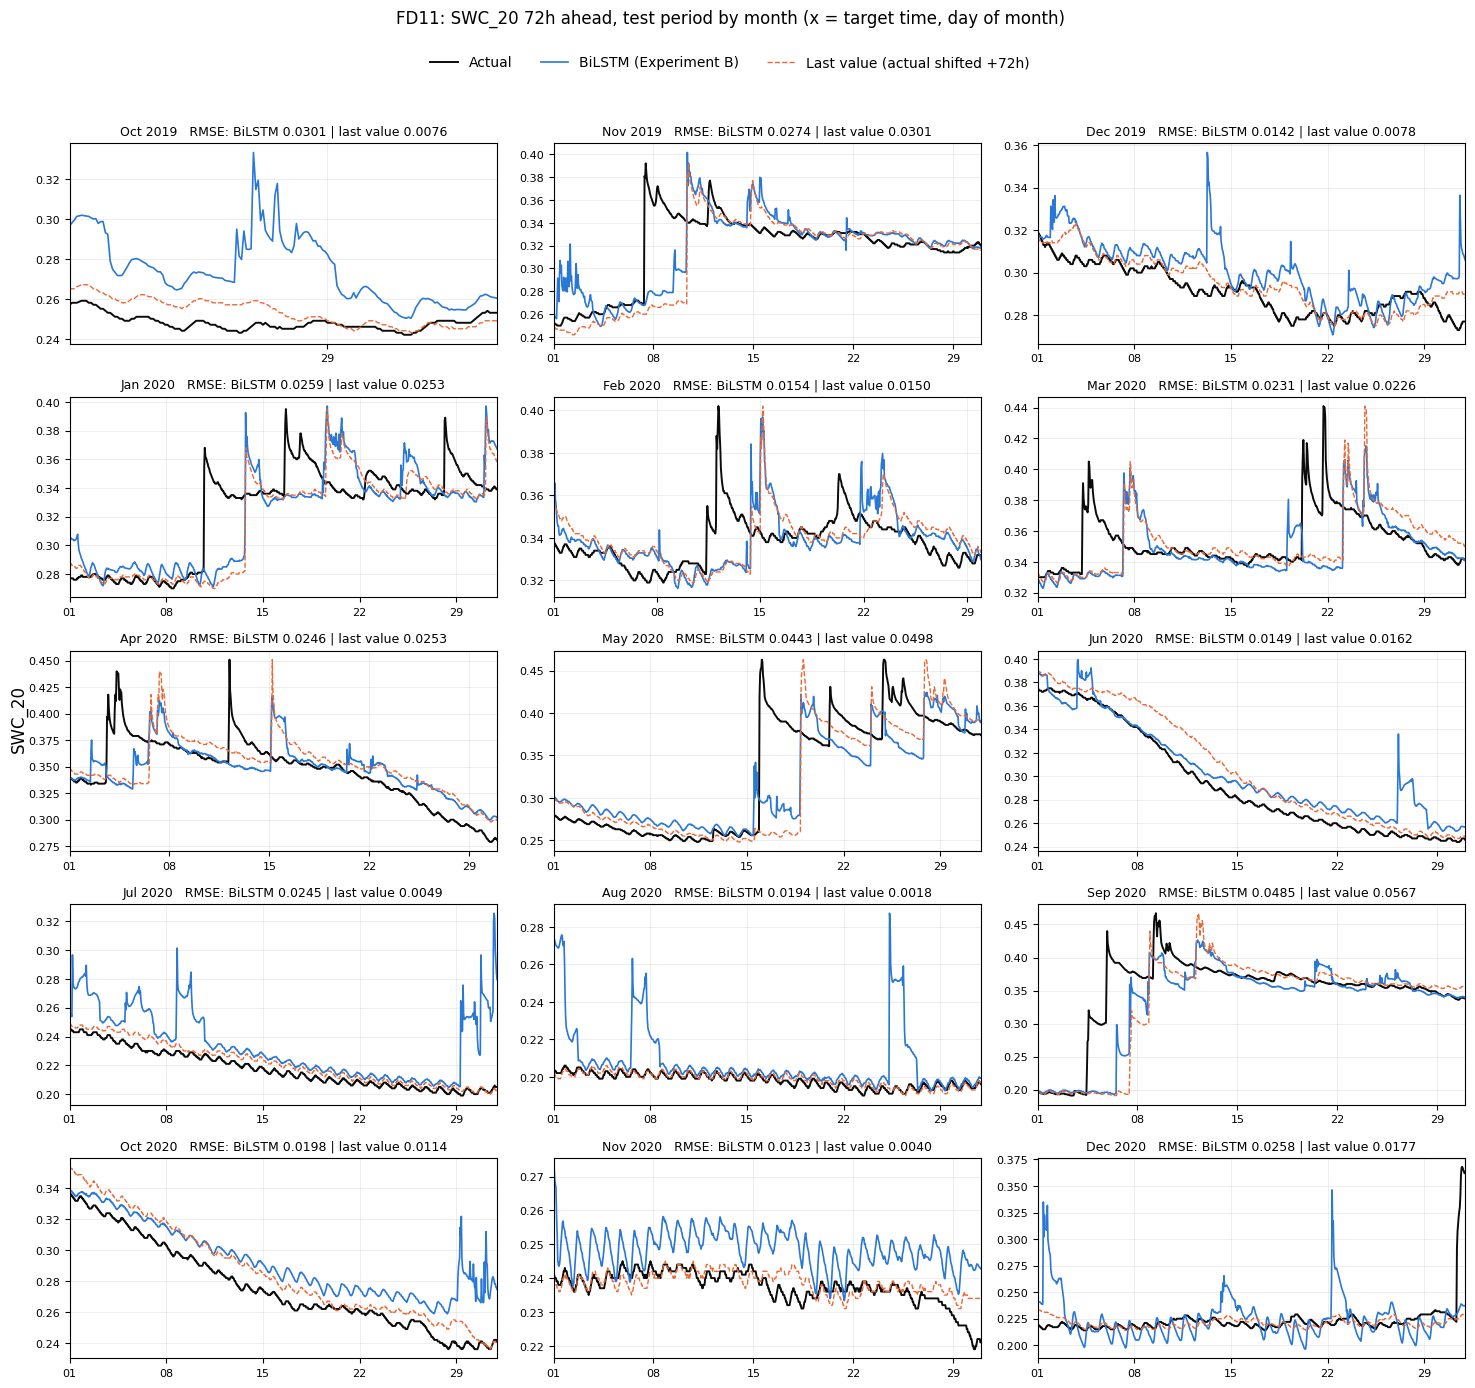

In [26]:
monthly = pd.DataFrame({"actual": t["y_true"], "bilstm": t["y_pred"], "last_value": naive_test["Last value"]},
                       index=t["target_time"])
months = monthly.index.to_period("M").unique()
ncols = 3
nrows = int(np.ceil(len(months) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 2.7 * nrows), squeeze=False)
for ax, month in zip(axes.flat, months):
    m = monthly[monthly.index.to_period("M") == month]
    ax.plot(m.index, m["actual"], color=C_ACTUAL, linewidth=1.4, label="Actual")
    ax.plot(m.index, m["bilstm"], color=C_MODEL, linewidth=1.2, label=f"BiLSTM ({EXPERIMENT_NAME})")
    ax.plot(m.index, m["last_value"], color=C_LAST, linewidth=1.0, linestyle="--",
            label=f"Last value (actual shifted +{HORIZON}h)")
    rmse_model = compute_metrics(m["actual"], m["bilstm"])["RMSE"]
    rmse_last = compute_metrics(m["actual"], m["last_value"])["RMSE"]
    ax.set_title(f"{month.strftime('%b %Y')}   RMSE: BiLSTM {rmse_model:.4f} | last value {rmse_last:.4f}",
                 fontsize=9)
    ax.set_xlim(m.index.min(), m.index.max())
    ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22, 29]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d"))
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.3, linewidth=0.5)
for ax in axes.flat[len(months):]:
    ax.set_visible(False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.suptitle(f"{STATION}: SWC_20 {HORIZON}h ahead, test period by month (x = target time, day of month)", y=1.025)
fig.supylabel("SWC_20")
plt.tight_layout(rect=(0, 0, 1, 0.975))
plt.show()